# 02 — Explore the first batch
Run notebook 01 first. This notebook reads `batch_0001` and explores its class balance, missing values, repeated patients and distributions. It does not train a model or change the database.

In [1]:
%matplotlib inline

In [2]:
import sys
from pathlib import Path
project = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

import seaborn as sns
from io import BytesIO


## Functions: settings
This is a copy; edit the source in 05_pipeline_walkthrough.ipynb. Run the cells in order. After saving edits in the source notebooks, run the synchronization command described in the README.

In [3]:
import os
from urllib.parse import quote_plus


In [4]:
def s3_client():
    import boto3
    return boto3.client('s3', endpoint_url=os.getenv('S3_ENDPOINT_URL','http://minio.mlops-project.svc.cluster.local:9000'), region_name='us-east-1', aws_access_key_id=os.environ['AWS_ACCESS_KEY_ID'], aws_secret_access_key=os.environ['AWS_SECRET_ACCESS_KEY'])


## Functions: preprocessing
This is a copy; edit the source in 03_preprocessing.ipynb. Run the cells in order. After saving edits in the source notebooks, run the synchronization command described in the README.

In [5]:
import hashlib
import numpy as np
import pandas as pd
NUMERIC_FEATURES = (
    'time_in_hospital', 'num_lab_procedures', 'num_procedures',
    'num_medications', 'number_outpatient', 'number_emergency',
    'number_inpatient', 'number_diagnoses',
)
SPLIT_STRATEGY = 'patient_nbr_sha256_70_15_15'


In [6]:
def split_for_patient(patient_id):
    value = int(hashlib.sha256(str(int(patient_id)).encode()).hexdigest()[:12], 16) % 10000
    return 'train' if value < 7000 else ('validation' if value < 8500 else 'test')


In [7]:
def normalize_features(features):
    """Keep categorical columns categorical, even when an entire batch is missing."""
    result = features.copy()
    result = result.mask(result.eq('?'))
    for column in result:
        if column in NUMERIC_FEATURES:
            result[column] = pd.to_numeric(result[column], errors='coerce').astype('float64')
        else:
            result[column] = result[column].map(
                lambda value: str(value) if pd.notna(value) else np.nan
            ).astype(object)
    return result


In [8]:
def prepare_records(df):
    required = {'encounter_id', 'patient_nbr', 'readmitted'}
    if not required.issubset(df.columns):
        raise ValueError(f'Missing columns: {required - set(df.columns)}')
    df = df.copy().reset_index(drop=True)
    df = df.mask(df.eq('?'))
    if df[['encounter_id', 'patient_nbr', 'readmitted']].isna().any().any():
        raise ValueError('Encounter ID, patient ID and readmission label are required')
    unexpected = set(df['readmitted'].unique()) - {'NO', '>30', '<30'}
    if unexpected:
        raise ValueError(f'Unexpected readmission labels: {unexpected}')
    df['target'] = df['readmitted'].eq('<30').astype('int8')
    df['split'] = df['patient_nbr'].map(split_for_patient)
    excluded = {'encounter_id', 'patient_nbr', 'readmitted', 'target', 'split', 'discharge_disposition_id'}
    features = normalize_features(df.drop(columns=[c for c in excluded if c in df.columns]))
    return df[['encounter_id', 'patient_nbr', 'target', 'split']], features


In [9]:
body = s3_client().get_object(Bucket='diabetes-source', Key='batches/batch_0001.csv')['Body'].read()
data = pd.read_csv(BytesIO(body), keep_default_na=False)
print(f'{len(data):,} encounters, {data.patient_nbr.nunique():,} patients')
print(f'Repeated patient encounters: {data.patient_nbr.duplicated().sum():,}')
display(data.head())

15,000 encounters, 11,886 patients
Repeated patient encounters: 3,114


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


## Target and missing values
The positive class is `<30`. A question mark in the source means missing data.

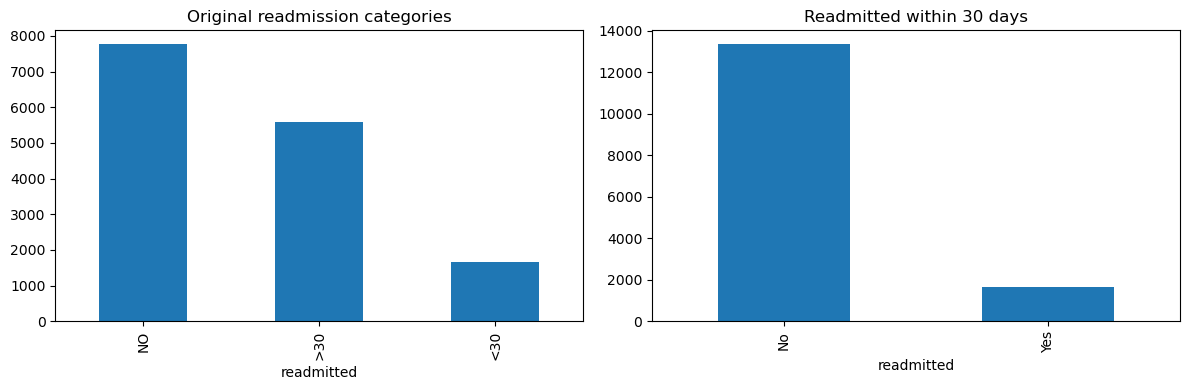

Positive rate: 11.0%


In [10]:
counts = data.readmitted.value_counts()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
counts.plot.bar(ax=axes[0], title='Original readmission categories')
data.readmitted.eq('<30').value_counts().rename(index={False: 'No', True: 'Yes'}).plot.bar(ax=axes[1], title='Readmitted within 30 days')
plt.tight_layout(); plt.show()
print(f'Positive rate: {data.readmitted.eq("<30").mean():.1%}')

/tmp/ipykernel_117/817047102.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  missing = data.replace('?', np.nan).isna().mean().sort_values(ascending=False)


,missing_pct
payer_code,100.000000
weight,96.926667
medical_specialty,38.960000
diag_3,2.860000
race,1.753333
diag_2,0.586667
diag_1,0.046667
admission_type_id,0.000000
patient_nbr,0.000000
encounter_id,0.000000


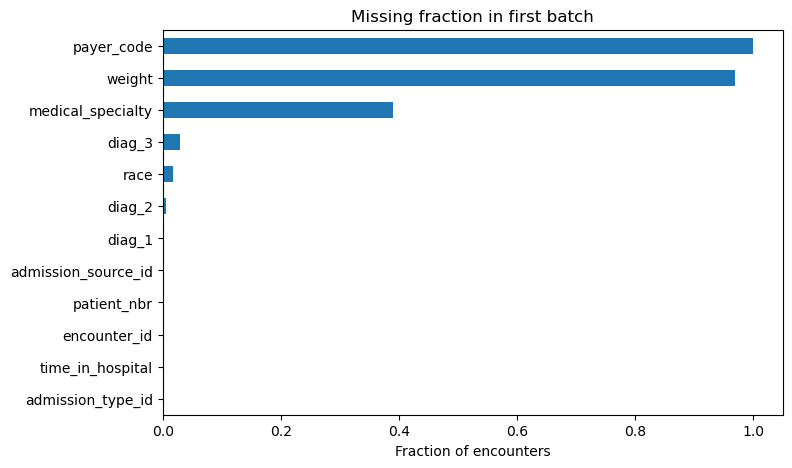

In [11]:
missing = data.replace('?', np.nan).isna().mean().sort_values(ascending=False)
display((missing.head(15) * 100).rename('missing_pct').to_frame())
missing.head(12).sort_values().plot.barh(figsize=(8, 5), title='Missing fraction in first batch')
plt.xlabel('Fraction of encounters'); plt.show()

## Patient separation and selected features
The same patient is assigned to a single split, even if they have multiple encounters. The split is deterministic across batches.

target,0,1,All
split,,,
test,2115,274,2389
train,9304,1146,10450
validation,1928,233,2161
All,13347,1653,15000


Patients appearing in multiple splits: 0


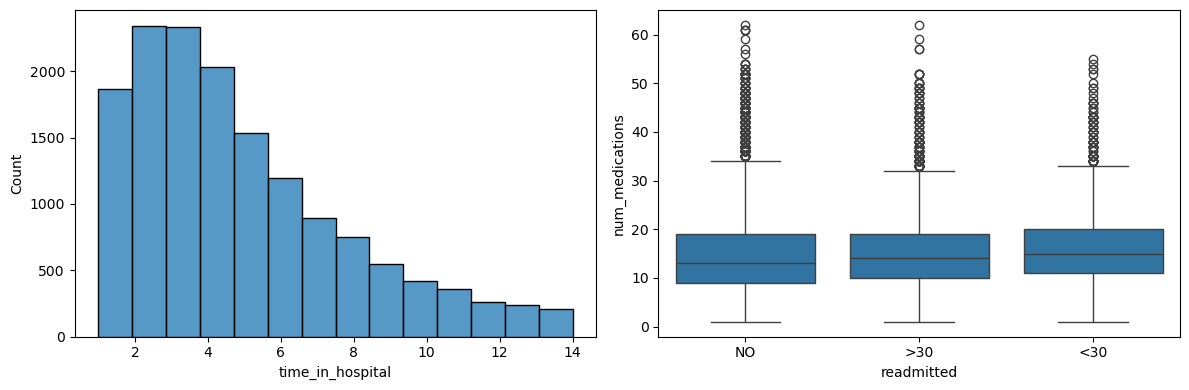

In [12]:
meta, features = prepare_records(data)
display(pd.crosstab(meta['split'], meta['target'], margins=True))
print('Patients appearing in multiple splits:', meta.groupby('patient_nbr')['split'].nunique().gt(1).sum())
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(data=data, x='time_in_hospital', bins=14, ax=axes[0])
sns.boxplot(data=data, x='readmitted', y='num_medications', ax=axes[1])
plt.tight_layout(); plt.show()

The dataset is observational and imbalanced. These models predict at the end of an admission because some features describe events during the hospital stay. Validate the dataset source and intended prediction time before drawing clinical conclusions.